## Medical Insurance cost prediction

In [ ]:
%pip install scikit-learn

In [ ]:
%pip install matplotlib

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

import joblib

In [9]:
import warnings
warnings.filterwarnings('ignore')

In [10]:
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

pd.set_option('display.max_columns', None)

In [11]:
df = pd.read_csv("/Users/mohitdutta/Downloads/DATASCIENCE/medical_insurance.csv")

In [12]:
df.shape

(2772, 7)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   str    
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   str    
 5   region    2772 non-null   str    
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 195.5 KB


In [15]:
df.describe()

,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


In [16]:
df.duplicated().sum()

np.int64(1435)

In [17]:
dup_counts=df.groupby(list(df.columns)).size().reset_index(name='count').sort_values(by='count', ascending=False)

In [18]:
dup_counts["count"].value_counts().sort_index()

count
2    1288
4      49
Name: count, dtype: int64

In [24]:
df.drop_duplicates().reset_index(drop=True)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1332,50,male,30.970,3,no,northwest,10600.54830
1333,18,female,31.920,0,no,northeast,2205.98080
1334,18,female,36.850,0,no,southeast,1629.83350
1335,21,female,25.800,0,no,southwest,2007.94500


In [28]:
for col in ["sex", "smoker", "region"]:
    print(f"---- {col} ----")
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True).round(3))

---- sex ----
sex
male      1406
female    1366
Name: count, dtype: int64
sex
male      0.507
female    0.493
Name: proportion, dtype: float64
---- smoker ----
smoker
no     2208
yes     564
Name: count, dtype: int64
smoker
no     0.797
yes    0.203
Name: proportion, dtype: float64
---- region ----
region
southeast    766
southwest    684
northwest    664
northeast    658
Name: count, dtype: int64
region
southeast    0.276
southwest    0.247
northwest    0.240
northeast    0.237
Name: proportion, dtype: float64


In [29]:
for col in ["age","bmi","children", "charges"]:
    print(f"{col}: skew={df[col].skew():.3f}, kurtosis={df[col].kurt():.3f}")

age: skew=0.062, kurtosis=-1.253
bmi: skew=0.280, kurtosis=-0.090
children: skew=0.955, kurtosis=0.259
charges: skew=1.511, kurtosis=1.566


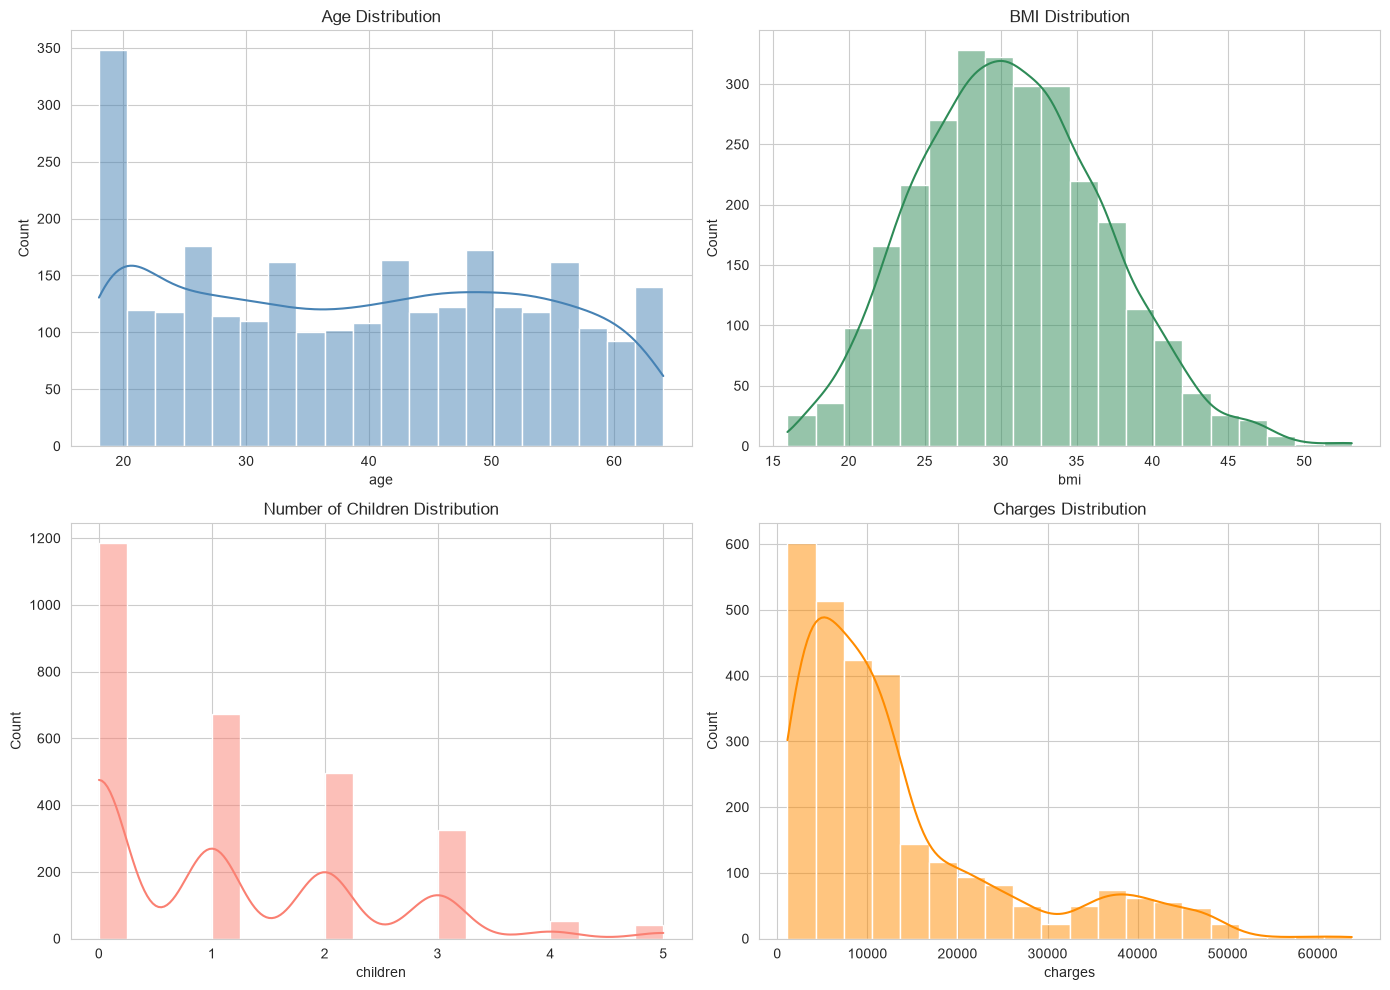

In [30]:
fig,axes=plt.subplots(2,2,figsize=(14,10))

sns.histplot(df['age'], bins=20, kde=True, ax=axes[0,0],color='steelblue')
axes[0,0].set_title('Age Distribution')

sns.histplot(df['bmi'], bins=20, kde=True, ax=axes[0,1],color='seagreen')
axes[0,1].set_title('BMI Distribution')

sns.histplot(df['children'], bins=20, kde=True, ax=axes[1,0],color='salmon')
axes[1,0].set_title('Number of Children Distribution')

sns.histplot(df['charges'], bins=20, kde=True, ax=axes[1,1],color='darkorange')
axes[1,1].set_title('Charges Distribution')

plt.tight_layout()

plt.show()

In [31]:
for col in ["bmi","charges"]:

    Q1,Q3 = df[col].quantile(0.25), df[col].quantile(0.75)

    IQR = Q3-Q1

    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR

    n_out= ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: bounds=({lower:.1f}, {upper:.1f}), outliers={n_out} ({n_out/len(df)*100:.1f}%)")

bmi: bounds=(13.4, 47.6), outliers=14 (0.5%)
charges: bounds=(-13147.2, 34412.8), outliers=296 (10.7%)


In [33]:
df.groupby('smoker')['charges'].agg(['mean','median','std','count'])

,mean,median,std,count
smoker,,,,
no,8417.874411,7341.4160,6015.568209,2208
yes,32223.139764,34725.8811,11521.258969,564


In [34]:
def bmi_category(bmi):
    if bmi < 18.5:
        return 'Underweight'
    elif 18.5 <= bmi < 25:
        return 'Normal weight'
    elif 25 <= bmi < 30:
        return 'Overweight'
    else:
        return 'Obese'

In [35]:
df['bmi_category'] = df['bmi'].apply(bmi_category)

In [36]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,Overweight
1,18,male,33.770,1,no,southeast,1725.55230,Obese
2,28,male,33.000,3,no,southeast,4449.46200,Obese
3,33,male,22.705,0,no,northwest,21984.47061,Normal weight
4,32,male,28.880,0,no,northwest,3866.85520,Overweight


In [38]:
df['bmi_category'].value_counts()

bmi_category
Obese            1470
Overweight        790
Normal weight     472
Underweight        40
Name: count, dtype: int64

In [42]:
df.groupby(['bmi_category'])['charges'].mean().sort_values().round(2)

bmi_category
Underweight       8852.20
Normal weight    10218.52
Overweight       11015.81
Obese            15565.17
Name: charges, dtype: float64

In [43]:
df["log_charges"] = np.log(df["charges"])

In [44]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category,log_charges
0,19,female,27.900,0,yes,southwest,16884.92400,Overweight,9.734176
1,18,male,33.770,1,no,southeast,1725.55230,Obese,7.453302
2,28,male,33.000,3,no,southeast,4449.46200,Obese,8.400538
3,33,male,22.705,0,no,northwest,21984.47061,Normal weight,9.998092
4,32,male,28.880,0,no,northwest,3866.85520,Overweight,8.260197


In [45]:
df['charges'].skew()

np.float64(1.511315043602352)

In [46]:
df['log_charges'].skew()

np.float64(-0.08908723369716186)

In [47]:
df_model=pd.get_dummies(
    df, 
    columns=['sex', 'smoker', 'region','bmi_category'], 
    drop_first=True
)

print(df_model.columns.to_list())

['age', 'bmi', 'children', 'charges', 'log_charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_Obese', 'bmi_category_Overweight', 'bmi_category_Underweight']


In [48]:
df_model.head()

,age,bmi,children,charges,log_charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_category_Obese,bmi_category_Overweight,bmi_category_Underweight
0,19,27.900,0,16884.92400,9.734176,False,True,False,False,True,False,True,False
1,18,33.770,1,1725.55230,7.453302,True,False,False,True,False,True,False,False
2,28,33.000,3,4449.46200,8.400538,True,False,False,True,False,True,False,False
3,33,22.705,0,21984.47061,9.998092,True,False,True,False,False,False,False,False
4,32,28.880,0,3866.85520,8.260197,True,False,True,False,False,False,True,False


In [49]:
features_cols =[ c for c in df_model.columns if c not in ['charges','log_charges']]

x=df_model[features_cols]

y=df_model['log_charges']

In [50]:
x_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

In [58]:
y_test_real=np.exp(y_test)

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, n_jobs=-1),
    "GradientBoostingRegressor": GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.5)
}

trained_models = {}
metrics_results = {}

from pyexpat import model
from unicodedata import name

y_test_real = np.exp(y_test)

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, max_depth=6, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, max_depth=3, learning_rate=0.5
    ),
}

trained_models = {}
metrics_rows = []

for model_name, model in candidate_models.items():
    model.fit(x_train, y_train)
    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)

    r2 = r2_score(y_test_real, y_pred)
    mae = mean_absolute_error(y_test_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_real, y_pred))

    trained_models[model_name] = model
    metrics_rows.append({
        "Model": model_name,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
    })

    print(f"Model: {model_name}, R2: {r2:.4f}, MAE: {mae:.2f}, RMSE: {rmse:.2f}")
    y_pred = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)

r2=r2_score(y_test_real, y_pred)
mae=mean_absolute_error(y_test_real, y_pred)
rsme=np.sqrt(mean_squared_error(y_test_real, y_pred))

trained_models[name] = model
metrics_rows.append({
    "Model": name,
    "R2": r2,
    "MAE": mae,
    "RMSE": rsme
})

print(f"Model: {name}, R2: {r2:.4f}, MAE: {mae:.2f}, RMSE: {rsme:.2f}")

Model: Linear Regression, R2: 0.5216, MAE: 4275.10, RMSE: 8369.92
Model: Random Forest, R2: 0.8763, MAE: 1891.17, RMSE: 4256.36
Model: Gradient Boosting, R2: 0.9103, MAE: 1699.02, RMSE: 3624.71
Model: <built-in function name>, R2: 0.9103, MAE: 1699.02, RMSE: 3624.71


In [59]:
results=pd.DataFrame(metrics_rows).sort_values(by='R2', ascending=False).reset_index(drop=True)

In [60]:
results.round(4)

,Model,R2,MAE,RMSE
0,Gradient Boosting,0.9103,1699.0174,3624.7126
1,<built-in function name>,0.9103,1699.0174,3624.7126
2,Random Forest,0.8763,1891.1710,4256.3641
3,Linear Regression,0.5216,4275.1013,8369.9198


In [61]:
best_model_name=results.loc[0,'Model']
best_model=trained_models[best_model_name]

In [62]:
best_model

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.5
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",300
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init in

In [63]:
joblib.dump(best_model, 'insurance_model.pkl')
joblib.dump(features_cols, 'model_features.pkl')
joblib.dump(best_model_name,'model_name.pkl')


['model_name.pkl']